# 00 · Exploración de fuentes SUBE

**Pregunta de esta etapa:** ¿tenemos datos públicos *reales* para detectar el tipo de anomalía
denunciada (secciones tarifarias infladas), o hay que simular esa capa?

Antes de aplicar cualquier método estadístico hay que saber *qué mide cada variable*.
Un detector de anomalías sobre una variable mal entendida produce conclusiones falsas con aspecto técnico.

> Encuadre: es una causa judicial abierta. Este proyecto demuestra métodos; no acusa a ninguna empresa.

In [1]:
import sys; sys.path.append('../src')
import pandas as pd, matplotlib.pyplot as plt
from io_sube import cargar_operaciones, cargar_usos, clave_linea
pd.set_option('display.width', 200)

## 1. Dataset de "operaciones de viaje" con *grupo tarifario*
Es el candidato a traer secciones. Veamos qué valores tiene realmente.

In [2]:
ops = cargar_operaciones()
print(ops.shape, '| períodos:', ops.periodo.min().date(), '→', ops.periodo.max().date())
ops.drop(columns=['EMPRESA', 'LINEA']).head()   # sin nombres de empresas ni líneas

(33508, 9) | períodos: 2013-01-01 → 2019-10-01


,PERIODO,MODO,JURISDICCION,grupo_tarifario,cantidad,ACTUALIZACION,periodo
0,201301,COLECTIVO,MUNICIPAL,-,12125,201903,2013-01-01
1,201301,COLECTIVO,MUNICIPAL,-,582547,201903,2013-01-01
2,201301,COLECTIVO,MUNICIPAL,-,890,201903,2013-01-01
3,201301,COLECTIVO,MUNICIPAL,-,217745,201903,2013-01-01
4,201301,COLECTIVO,MUNICIPAL,-,295326,201903,2013-01-01


In [3]:
col = ops[ops.MODO == 'COLECTIVO']
(col.groupby(['grupo_tarifario', 'JURISDICCION']).cantidad.sum()
    .unstack().fillna(0).div(1e6).round(1))

JURISDICCION,(en blanco),FFCC,MUNICIPAL,NACIONAL,PROVINCIAL
grupo_tarifario,,,,,
-,4.8,0.0,235.1,0.0,106.3
D.F.,0.0,0.0,0.0,2266.4,0.0
S.G.I.,0.0,0.0,0.0,8172.8,0.0
S.G.II.,0.0,0.0,0.0,340.6,0.0
U.M.A.1.,0.0,0.0,3422.4,0.0,3.4
U.M.A.2.,0.0,0.0,1039.6,1.3,0.0
U.P.A.,0.0,0.0,0.0,0.0,6031.5
U.P.A.M,0.0,0.0,0.0,0.0,1077.7


**Lectura:** los "grupos tarifarios" (`S.G.I.`, `U.P.A.`, `U.M.A.1.`…) dependen de la **jurisdicción**
(nacional / provincial / municipal) y están definidos "según normativa" (diccionario oficial).
Son categorías administrativas del régimen tarifario, **no secciones por distancia recorrida**.
Además la serie termina en 2019.

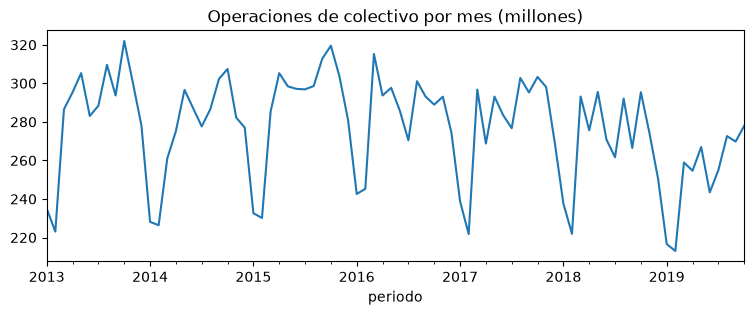

In [4]:
col.groupby('periodo').cantidad.sum().div(1e6).plot(figsize=(9,3), title='Operaciones de colectivo por mes (millones)')
plt.show()

## 2. Transacciones diarias por línea (2020 → 2026)

In [5]:
usos = cargar_usos()
bus = usos[(usos.TIPO_TRANSPORTE == 'COLECTIVO') & (usos.AMBA == 'SI')].copy()
print('Cobertura:', usos.DIA_TRANSPORTE.min().date(), '→', usos.DIA_TRANSPORTE.max().date())
print('Líneas AMBA colectivo:', bus.LINEA.nunique(), '| empresas:', bus.NOMBRE_EMPRESA.nunique())
print('Primer día con dato preliminar:', bus[bus.DATO_PRELIMINAR == 'SI'].DIA_TRANSPORTE.min().date())
bus.drop(columns=['NOMBRE_EMPRESA', 'LINEA']).head()   # sin nombres de empresas ni líneas

Cobertura: 2020-01-01 → 2026-10-27
Líneas AMBA colectivo: 484 | empresas: 163
Primer día con dato preliminar: 2026-02-01


,DIA_TRANSPORTE,AMBA,TIPO_TRANSPORTE,JURISDICCION,PROVINCIA,MUNICIPIO,CANTIDAD,DATO_PRELIMINAR
1,2020-01-01,SI,COLECTIVO,PROVINCIAL,BUENOS AIRES,SN,1492,NO
3,2020-01-01,SI,COLECTIVO,MUNICIPAL,BUENOS AIRES,ALMIRANTE BROWN,4669,NO
4,2020-01-01,SI,COLECTIVO,MUNICIPAL,BUENOS AIRES,LANUS,187,NO
5,2020-01-01,SI,COLECTIVO,MUNICIPAL,BUENOS AIRES,LANUS,543,NO
6,2020-01-01,SI,COLECTIVO,NACIONAL,JN,SD,1927,NO


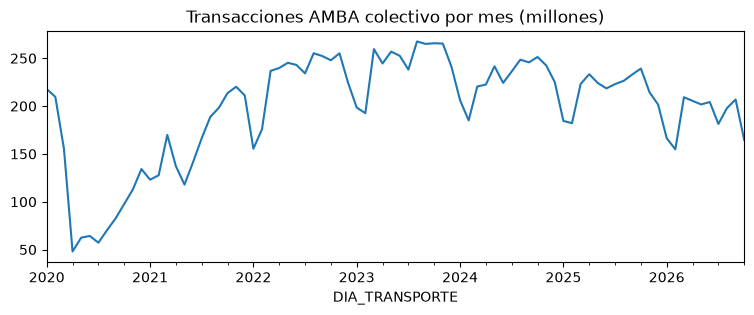

,viajes,lineas
DIA_TRANSPORTE,,
2026-05,201711580,379
2026-06,204275276,381
2026-07,181347585,377
2026-08,197913966,377
2026-09,206897112,378
2026-10,164617456,378


In [6]:
mensual = bus.groupby(bus.DIA_TRANSPORTE.dt.to_period('M')).agg(viajes=('CANTIDAD','sum'), lineas=('LINEA','nunique'))
mensual.viajes.div(1e6).plot(figsize=(9,3), title='Transacciones AMBA colectivo por mes (millones)'); plt.show()
mensual.tail(6)

Este dataset llega a octubre 2026 y tiene línea, empresa, jurisdicción y municipio, pero **solo cantidad de
transacciones**: no hay monto cobrado ni sección. Sirve para el panel línea × mes, no para medir tarifa media.

## 3. Consistencia de nombres de línea entre datasets

In [7]:
ko = set(col.LINEA.map(clave_linea))
u20 = bus[bus.DIA_TRANSPORTE.dt.year == 2020]
ku = set(u20.LINEA.map(clave_linea))
print('Exactas (sin normalizar):', len(set(col.LINEA.str.upper()) & set(u20.LINEA.str.upper())))
print('Con clave normalizada:  ', len(ko & ku), 'de', len(ku), 'líneas de usos 2020')
w = u20.assign(k=u20.LINEA.map(clave_linea)).groupby('k').CANTIDAD.sum()
print(f'Viajes 2020 cubiertos: {w[w.index.isin(ko)].sum() / w.sum():.1%}')

Exactas (sin normalizar): 30
Con clave normalizada:   361 de 380 líneas de usos 2020
Viajes 2020 cubiertos: 97.4%


## Conclusión
| Necesito | ¿Dato público? |
|---|---|
| Panel línea × mes hasta 2026 | Sí (usos diarios) |
| Grupo tarifario | Sí, pero hasta 2019 y **no es sección** |
| Viajes por sección / monto cobrado | **No** |

**Decisión:** la Fase 2 usa **secciones simuladas** sobre el panel real de líneas. Ver `docs/fuentes.md`.